# Praktikum 2

In [1]:
import numpy as np
import pandas as pd

# Memuat dataset PBL dengan dua fitur diskrit non-negatif untuk perbandingan MultinomialNB dan GaussianNB
raw_df = pd.read_csv('burnout_dataset1.csv')
df_clean = raw_df[['Work_Hours_Per_Week', 'Anxiety_Score', 'Burnout_Risk']].dropna().copy()

X = df_clean[['Work_Hours_Per_Week', 'Anxiety_Score']].round().astype(int).to_numpy()
y = (df_clean['Burnout_Risk'] == 'High').astype(int).to_numpy()

# Cek hasil
print(X[:10])
print(y[:10])

[[67 74]
 [44 58]
 [60 54]
 [25 12]
 [52 25]
 [64 59]
 [70 42]
 [51 65]
 [63 18]
 [35 23]]
[1 0 0 0 0 1 0 0 0 0]


In [2]:
# Reshape label y menjadi 2D untuk digabungkan dengan fitur X
y_new = y.reshape(len(y), 1)
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Work_Hours_Per_Week', 'Anxiety_Score', 'Label']

# Buat DataFrame
df = pd.DataFrame(data, columns=nama_kolom)
df.head()

,Work_Hours_Per_Week,Anxiety_Score,Label
0,67,74,1
1,44,58,0
2,60,54,0
3,25,12,0
4,52,25,0


In [3]:
# Definisikan nama label
labels = {
    1: 'High Burnout',
    0: 'Non-High Burnout'
}

df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)
df_label.head()

,Work_Hours_Per_Week,Anxiety_Score,Label
0,67,74,High Burnout
1,44,58,Non-High Burnout
2,60,54,Non-High Burnout
3,25,12,Non-High Burnout
4,52,25,Non-High Burnout


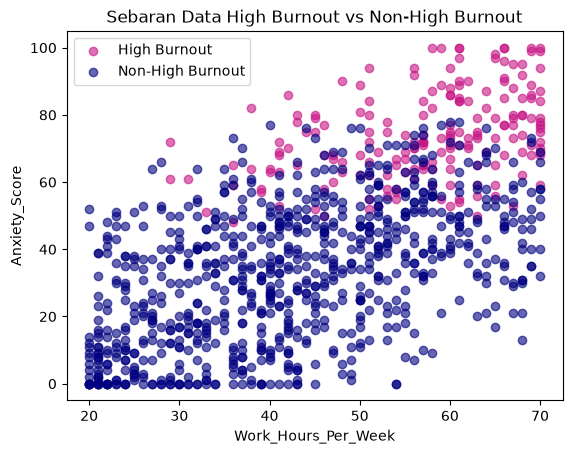

In [4]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'high': 'MediumVioletRed',
    'non_high': 'Navy'
}

# Gunakan sampel 1000 titik agar scatter plot jelas terbaca
df_plot = df_label.sample(n=1000, random_state=30)
gb = df_plot.groupby('Label')
class_high = gb.get_group('High Burnout')
class_non_high = gb.get_group('Non-High Burnout')

plt.scatter(x=class_high['Work_Hours_Per_Week'], y=class_high['Anxiety_Score'], c=colors['high'], alpha=0.6)
plt.scatter(x=class_non_high['Work_Hours_Per_Week'], y=class_non_high['Anxiety_Score'], c=colors['non_high'], alpha=0.6)
plt.xlabel('Work_Hours_Per_Week')
plt.ylabel('Anxiety_Score')
plt.legend(['High Burnout', 'Non-High Burnout'])
plt.title('Sebaran Data High Burnout vs Non-High Burnout')
plt.show()

In [5]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

mnb = MultinomialNB()

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dan evaluasi training
y_train_pred = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi dan evaluasi testing
y_test_pred = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.8034843205574913
Hasil akurasi data test: 0.8080623306233062


In [6]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()

# Fit model menggunakan split yang sama
gnb.fit(X_train, y_train)

# Prediksi dan evaluasi training
y_train_pred_gnb = gnb.predict(X_train)
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi dan evaluasi testing
y_test_pred_gnb = gnb.predict(X_test)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.9038617886178861
Hasil akurasi data test (Gaussian): 0.9029810298102982
